# Esplorazione iniziale di TEM-1

Questo notebook estrae embedding del wild type con ESM-2 150M ed esplora i dati DMS. Non implementa un predittore supervisionato delle varianti. Per metodo, benchmark e istruzioni fare riferimento al [README](README.md).

Avviare dalla radice di `Bioscience-PLM`: le celle usano `TEM1.fasta` e `proteingym_substitutions.zip` nella directory corrente. Il FASTA viene scaricato e riscritto; lo ZIP viene scaricato soltanto se assente. L’inferenza esplorativa usa CPU e il checkpoint non è fissato a un commit: per il confronto riproducibile usare la pipeline descritta nel README.


In [ ]:
import torch
from transformers import AutoTokenizer, EsmModel
from Bio import SeqIO

import requests
import os
import pandas as pd
import zipfile

In [ ]:
model_name = "facebook/esm2_t30_150M_UR50D"

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Modello ESM-2 150M
model = EsmModel.from_pretrained(model_name)

# Modalità valutazione
model.eval()

print("Model loaded!")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

c:\Users\Giulio\Desktop\UNIVERSITA\Bioscience-PLM\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Giulio\.cache\huggingface\hub\models--facebook--esm2_t30_150M_UR50D. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Giulio\Desktop\UNIVERSITA\Bioscience-PLM\.venv\Lib\site-packages\huggingfa

Modello caricato!
Parametri: 148,138,841


In [9]:
url = "https://rest.uniprot.org/uniprotkb/P62593.fasta"

response = requests.get(url)
response.raise_for_status()

with open("TEM1.fasta", "w") as f:
    f.write(response.text)

print(response.text)

>sp|P62593|BLAT_ECOLX Beta-lactamase TEM OS=Escherichia coli OX=562 GN=bla PE=1 SV=1
MSIQHFRVALIPFFAAFCLPVFAHPETLVKVKDAEDQLGARVGYIELDLNSGKILESFRP
EERFPMMSTFKVLLCGAVLSRVDAGQEQLGRRIHYSQNDLVEYSPVTEKHLTDGMTVREL
CSAAITMSDNTAANLLLTTIGGPKELTAFLHNMGDHVTRLDRWEPELNEAIPNDERDTTM
PAAMATTLRKLLTGELLTLASRQQLIDWMEADKVAGPLLRSALPAGWFIADKSGAGERGS
RGIIAALGPDGKPSRIVVIYTTGSQATMDERNRQIAEIGASLIKHW



In [14]:
record = SeqIO.read("TEM1.fasta", "fasta")
sequence = str(record.seq)

print("Sequence length:", len(sequence))

Sequence length: 286


In [17]:
device = "cpu"

inputs = tokenizer(
    sequence,
    return_tensors="pt"
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

embeddings = outputs.last_hidden_state

print("Embedding shape:", embeddings.shape)

Embedding shape: torch.Size([1, 288, 640])


In [ ]:
url = (
    "https://marks.hms.harvard.edu/proteingym/"
    "ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip"
)

zip_path = "proteingym_substitutions.zip"

if not os.path.exists(zip_path):
    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024*1024):
            if chunk:
                f.write(chunk)

print("Download completato!")

Download completato!


In [ ]:
with zipfile.ZipFile(zip_path, "r") as z:

    files = z.namelist()

    candidates = [
        f for f in files
        if "BLAT_ECOLX" in f.upper()
        or "TEM1" in f.upper()
        or "TEM-1" in f.upper()
    ]

    for f in candidates:
        print(f)

DMS_ProteinGym_substitutions/BLAT_ECOLX_Jacquier_2013.csv
DMS_ProteinGym_substitutions/BLAT_ECOLX_Firnberg_2014.csv
DMS_ProteinGym_substitutions/BLAT_ECOLX_Deng_2012.csv
DMS_ProteinGym_substitutions/BLAT_ECOLX_Stiffler_2015.csv


In [46]:
file = "DMS_ProteinGym_substitutions/BLAT_ECOLX_Stiffler_2015.csv"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(file) as f:
        df = pd.read_csv(f)

print("Numero varianti:", len(df))
print("\nColonne:")
print(df.columns.tolist())

df.head()

Numero varianti: 4996

Colonne:
['mutant', 'mutated_sequence', 'DMS_score', 'DMS_score_bin']


,mutant,mutated_sequence,DMS_score,DMS_score_bin
0,H24C,MSIQHFRVALIPFFAAFCLPVFACPETLVKVKDAEDQLGARVGYIE...,-0.418260,1
1,H24Y,MSIQHFRVALIPFFAAFCLPVFAYPETLVKVKDAEDQLGARVGYIE...,-0.885025,1
2,H24W,MSIQHFRVALIPFFAAFCLPVFAWPETLVKVKDAEDQLGARVGYIE...,-1.347586,0
3,H24V,MSIQHFRVALIPFFAAFCLPVFAVPETLVKVKDAEDQLGARVGYIE...,-0.026874,1
4,H24T,MSIQHFRVALIPFFAAFCLPVFATPETLVKVKDAEDQLGARVGYIE...,-0.067188,1


In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4996 entries, 0 to 4995
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mutant            4996 non-null   str    
 1   mutated_sequence  4996 non-null   str    
 2   DMS_score         4996 non-null   float64
 3   DMS_score_bin     4996 non-null   int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 156.3 KB


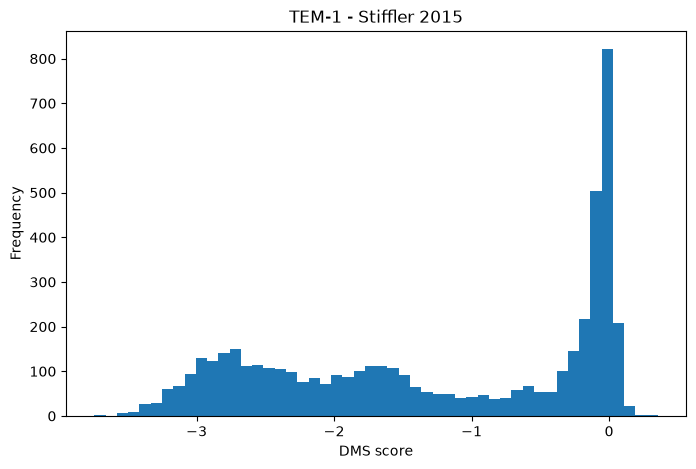

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["DMS_score"].dropna(), bins=50)

plt.xlabel("DMS score")
plt.ylabel("Frequency")
plt.title("TEM-1 - Stiffler 2015")

plt.show()